# Experiment C — Physically constrained probe–frequency pair selection

**Question:** For each of the 27 frequencies, which upstream–downstream pair (UUS/US × DS/DDS) has the most reproducible **healthy Stage 1 residuals**, and which pairs also respond to leaks?

**No Stage 2 retraining or modification.** Reuses the original Stage 1 checkpoint, coordinate definitions, frequency ordering, 40-step history, and scaling from Experiment A. Evaluates four candidate pairs × 27 frequencies = **108 pair-frequency candidates**.

**Critical:** Training run `1211_1` and evaluation run `1212_1` differ in physical setup (including probe coordinates and hole sizes). Their comparison is descriptive, not a controlled experiment. The evaluation run is used for *diagnostics*, **not** for selecting a final model without independent holdout validation. Leak discriminability is computed only if labeled leak samples are available and is not automatically evidence of leak causality.

Run from project root or `notebooks/`. Outputs: `results/experiment_C_probe_frequency_pairs/`.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch


# USER CONFIGURATION
EXPERIMENT = "1212_1"          # original validation experiment; 1211_1 was training
WINDOW_SIZE = 40
BATCH_SIZE = 64               # reduce to 16 or 32 if memory constrained
THRESHOLD = 0.5               # NOT the author's optimized validation threshold
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PROBE_ORDER = ["UUS", "US", "DS", "DDS"]

# Works whether Jupyter's working directory is project/notebooks or project/.
start = Path.cwd().resolve()
candidates = [start, start.parent]
PROJECT_ROOT = next((p for p in candidates
                     if (p / "data" / "2026-03-04").is_dir() and (p / "models").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"Cannot find project root from {start}. Expected data/2026-03-04 and models/ "
        "under the working directory or its parent."
    )
DATA_DIR = PROJECT_ROOT / "data" / "2026-03-04"
MODELS_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR = PROJECT_ROOT / "results" / "experiment_C_probe_frequency_pairs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BASELINE_PATH = MODELS_DIR / "leak_detect_baseline.pt"
RESIDUAL_PATH = MODELS_DIR / "leak_detect_residual.pt"

for path in [BASELINE_PATH] + [DATA_DIR / f"{p}{EXPERIMENT}.csv" for p in PROBE_ORDER]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing required file: {path}")
print("Project:", PROJECT_ROOT)
print("Data:", DATA_DIR)
print("Device:", DEVICE)
print("Output:", OUTPUT_DIR)
# Optional: choose frequencies to inspect. None means automatic top-error frequencies.
PLOT_FREQUENCIES = None  # e.g. ["f80", "f100", "f250"]
PLOT_PROBES = PROBE_ORDER
TOP_N_FREQUENCIES = 5
TRANSITION_THRESHOLD = 0.0  # abs(Re[t]-Re[t-1]) > threshold
MAX_LAG = 15  # descriptive cross-correlation; time steps, not seconds


Project: /home/ubuntu/notebooks/Leak_Detection
Data: /home/ubuntu/notebooks/Leak_Detection/data/2026-03-04
Device: cpu
Output: /home/ubuntu/notebooks/Leak_Detection/results/experiment_C_probe_frequency_pairs


In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class BaselineSpectralModel(nn.Module):
    def __init__(
        self,
        Freq=27,
        hidden_dim=64,
        re_feat_dim=16,
        coord_feat_dim=16
    ):
        super().__init__()

        self.Freq = Freq
        self.hidden_dim = hidden_dim
        self.re_feat_dim = re_feat_dim
        self.coord_feat_dim = coord_feat_dim

        self.re_embed = nn.Sequential(
            nn.Linear(1, re_feat_dim),
            nn.ReLU()
        )

        self.coord_embed = nn.Sequential(
            nn.Linear(2, coord_feat_dim),
            nn.ReLU()
        )

        self.re_lstm = nn.LSTM(
            input_size=re_feat_dim + coord_feat_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True
        )

        self.re_to_spec = nn.Linear(hidden_dim, Freq)

    def forward(self, X_window, Re_window, coords):

        B, W, P, F = X_window.shape
        assert F == self.Freq

        # Build per-probe inputs in batched form
        re_p = Re_window.unsqueeze(-1).unsqueeze(-1).expand(-1, -1, P, 1)   # (B,W,P,1)
        coord_p = coords.unsqueeze(1).expand(-1, W, -1, -1)                  # (B,W,P,2)

        re_feat = self.re_embed(re_p)                                         # (B,W,P,Cr)
        coord_feat = self.coord_embed(coord_p)                                # (B,W,P,Cc)

        probe_in = torch.cat([re_feat, coord_feat], dim=-1)                   # (B,W,P,Cr+Cc)

        # Move P into batch: (B,W,P,D) -> (B*P,W,D)
        D = probe_in.shape[-1]
        probe_in = probe_in.permute(0, 2, 1, 3).contiguous()                  # (B,P,W,D)
        probe_in = probe_in.view(B * P, W, D)                                 # (B*P,W,D)

        # Shared LSTM over each probe independently
        probe_feats, _ = self.re_lstm(probe_in)                               # (B*P,W,H)

        # Reshape back: (B*P,W,H) -> (B,W,P,H)
        H = probe_feats.shape[-1]
        probe_feats = probe_feats.view(B, P, W, H)                            # (B,P,W,H)
        probe_feats = probe_feats.permute(0, 2, 1, 3).contiguous()            # (B,W,P,H)

        X_hat = self.re_to_spec(probe_feats)                                  # (B,W,P,F)

        return {"baseline": X_hat}

In [3]:
PROBE_COORDS = {
    "1212_1": {
        "UUS": [-4.1275, 0.0250], "US": [-0.4572, 0.0250],
        "DS": [0.4572, 0.0250], "DDS": [1.9177, 0.0250],
    },
    "1211_1": {
        "UUS": [-3.0226, 0.0250], "US": [-0.4572, 0.0250],
        "DS": [0.4572, 0.0250], "DDS": [3.0226, 0.0250],
    },
}
HOLE_SIZES = {"1212_1": 4.0, "1211_1": 2.0}


def read_sensor_csv(path):
    df = pd.read_csv(path, low_memory=False)
    if len(df.columns) == 1:
        raise ValueError(f"Only one column found in {path.name}; check CSV delimiter/format.")
    df.columns = [str(c).strip() for c in df.columns]
    return df


def load_experiment(experiment):
    if experiment not in PROBE_COORDS:
        raise ValueError(f"Coordinates not configured for experiment {experiment}")
    dfs = {p: read_sensor_csv(DATA_DIR / f"{p}{experiment}.csv") for p in PROBE_ORDER}

    # Match the original frequency extraction: e.g. '...ǀf1000' -> 'f1000'.
    def frequency_map(df):
        result = {}
        for col in df.columns:
            if "ǀf" in col:
                label = col.split("ǀ")[1]
                if re.fullmatch(r"f[0-9]+(?:_[0-9]+)?", label):
                    result[label] = col
        return result

    freq_maps = {p: frequency_map(df) for p, df in dfs.items()}
    common_freqs = sorted(set.intersection(*(set(m) for m in freq_maps.values())),
                          key=lambda s: float(s[1:].replace("_", ".")))
    if len(common_freqs) != 27:
        raise ValueError(f"Expected 27 common frequencies; found {len(common_freqs)}: {common_freqs}")

    # Original notebook picks a reference dataframe from the grouped probe list.
    # Here use UUS explicitly and check alignment across all probes.
    ref = dfs["UUS"]
    time_col = "Date-Time"
    leak_col = "Leak Event"
    if time_col not in ref or leak_col not in ref:
        raise KeyError(f"Expected columns {time_col!r}, {leak_col!r} in UUS file; got {list(ref.columns)}")
    re_col = next((c for c in ref.columns if "Re" in c or "re" in c), None)
    if re_col is None:
        raise KeyError("No Reynolds-number column found (original notebook searches for 'Re' or 're').")

    min_T = min(len(df) for df in dfs.values())
    if len(set(len(df) for df in dfs.values())) != 1:
        print("WARNING: Unequal sensor lengths; truncating all to", min_T, "(original notebook behavior).")
    time = pd.to_datetime(ref[time_col].iloc[:min_T], errors="raise")
    if time.isna().any():
        raise ValueError("Missing timestamps in reference file")
    for p in PROBE_ORDER[1:]:
        other_time = pd.to_datetime(dfs[p][time_col].iloc[:min_T], errors="raise")
        if not np.array_equal(time.to_numpy(), other_time.to_numpy()):
            raise ValueError(f"Timestamps are not aligned between UUS and {p}. Do not infer on misaligned sensors.")
        if leak_col in dfs[p]:
            a = pd.to_numeric(ref[leak_col].iloc[:min_T], errors="coerce").fillna(0).to_numpy() > 0
            b = pd.to_numeric(dfs[p][leak_col].iloc[:min_T], errors="coerce").fillna(0).to_numpy() > 0
            if not np.array_equal(a, b):
                raise ValueError(f"Leak Event labels disagree between UUS and {p}")

    values = []
    for p in PROBE_ORDER:
        columns = [freq_maps[p][f] for f in common_freqs]
        x = dfs[p][columns].iloc[:min_T].apply(pd.to_numeric, errors="coerce").fillna(0.0)
        values.append(x.to_numpy(dtype=np.float32))
    X_raw = np.stack(values, axis=1)     # (T, 4, 27)
    re_raw = pd.to_numeric(ref[re_col].iloc[:min_T], errors="coerce").fillna(0).to_numpy(dtype=np.float32)
    leak = (pd.to_numeric(ref[leak_col].iloc[:min_T], errors="coerce").fillna(0).to_numpy() > 0).astype(np.float32)
    coords = np.array([PROBE_COORDS[experiment][p] for p in PROBE_ORDER], dtype=np.float32)

    return {
        "iteration": experiment,
        "X": torch.from_numpy(X_raw / 50.0),  # exact original normalization
        "Re": torch.from_numpy(re_raw / 150.0),
        "coords": torch.from_numpy(coords),
        "leak_open": leak,
        "datetime": time.to_numpy(),
        "frequency_labels": common_freqs,
        "re_column": re_col,
        "raw_rows": min_T,
    }



In [4]:
# State dictionaries saved by torch.save(model.state_dict(), path), as in the original notebook.
# weights_only=True is preferred for security (PyTorch >=2.0); fall back for older versions.
def load_weights(path):
    try:
        obj = torch.load(path, map_location="cpu", weights_only=True)
    except TypeError:
        obj = torch.load(path, map_location="cpu")
    if not isinstance(obj, dict):
        raise TypeError(f"{path.name} is not a state dictionary")
    if "state_dict" in obj and isinstance(obj["state_dict"], dict):
        obj = obj["state_dict"]
    return obj

baseline_model = BaselineSpectralModel(Freq=27, hidden_dim=64, re_feat_dim=16, coord_feat_dim=16)
baseline_model.load_state_dict(load_weights(BASELINE_PATH), strict=True)
baseline_model = baseline_model.to(DEVICE).eval()
print("Loaded Stage 1:", BASELINE_PATH.name)


Loaded Stage 1: leak_detect_baseline.pt


## 1. Predict all eligible windows and label them

Healthy windows require all 40 timestamps to be healthy. Leak windows require all 40 timestamps to be leak-labeled; mixed windows are excluded to avoid conflating transitions. The model is not trained here. The Stage 1 checkpoint was trained on healthy data, so predictions during leaks are used only to assess residual response.

In [5]:
RUNS = ["1211_1", "1212_1"]
PAIRS = [(u, d) for u in ("UUS", "US") for d in ("DS", "DDS")]
PLOT_TOP_N = 12
MIN_SAMPLES_PER_CLASS = 40
EPS = 1e-8

@torch.inference_mode()
def infer_labeled_windows(sample, batch_size=BATCH_SIZE):
    X, Re = sample['X'], sample['Re']
    W = WINDOW_SIZE
    leak = np.asarray(sample['leak_open'], dtype=bool)
    all_healthy = np.convolve((~leak).astype(int), np.ones(W,dtype=int),mode='valid') == W
    all_leak = np.convolve(leak.astype(int), np.ones(W,dtype=int),mode='valid') == W
    selected = np.flatnonzero(all_healthy | all_leak)
    if not len(selected): raise ValueError('No pure healthy/leak windows')
    coords = sample['coords'].unsqueeze(0).to(DEVICE)
    actual, pred = [], []
    # Construct batches lazily to avoid materializing all overlapping windows in RAM.
    for k in range(0,len(selected),batch_size):
        ix = selected[k:k+batch_size]
        xw = torch.stack([X[int(i):int(i)+W] for i in ix]).to(DEVICE)
        rew = torch.stack([Re[int(i):int(i)+W] for i in ix]).to(DEVICE)
        p = baseline_model(xw,rew,coords.expand(len(ix),-1,-1))['baseline'][:,-1]
        actual.append((xw[:,-1]*50).cpu().numpy())
        pred.append((p*50).cpu().numpy())
    actual=np.concatenate(actual); pred=np.concatenate(pred)
    endpoint=selected+W-1
    return dict(actual=actual,predicted=pred,residual=actual-pred,
                endpoint=endpoint,Re=sample['Re'].numpy()[endpoint]*150,
                label=np.where(all_leak[selected], 'leak', 'healthy'),
                time=pd.to_datetime(sample['datetime'][endpoint]),
                frequencies=sample['frequency_labels'])

runs={}
for run in RUNS:
    sample=load_experiment(run)
    runs[run]=infer_labeled_windows(sample)
    vals=pd.Series(runs[run]['label']).value_counts().to_dict()
    print(run, 'pure windows:',vals, 'frequency count:',len(runs[run]['frequencies']))
if runs[RUNS[0]]['frequencies']!=runs[RUNS[1]]['frequencies']:
    raise ValueError('Frequency ordering differs between runs')
FREQS=runs[RUNS[0]]['frequencies']


1211_1 pure windows: {'healthy': 7567, 'leak': 2805} frequency count: 27
1212_1 pure windows: {'healthy': 7567, 'leak': 2805} frequency count: 27


## 2. Individual-channel and paired healthy stability

For each run, channel bias = mean residual, noise = residual standard deviation, and RMSE = root mean squared residual. Pair contrast residual = upstream residual − downstream residual. Cross-run stability uses the difference in means and standard deviations, with Reynolds-matched comparisons to reduce confounding from different operating regimes. **Small signed mean alone is not stability.**

In [6]:
def summarize(a):
    a=np.asarray(a,dtype=float)
    return dict(n=len(a),mean=float(np.mean(a)),sd=float(np.std(a,ddof=1)) if len(a)>1 else np.nan,
                rmse=float(np.sqrt(np.mean(a*a))),mae=float(np.mean(np.abs(a))),
                p95_abs=float(np.quantile(np.abs(a),.95)))

channel_rows=[];pair_rows=[]
for run,dat in runs.items():
    mask=dat['label']=='healthy';r=dat['residual'][mask]
    for j,f in enumerate(FREQS):
        for p in PROBE_ORDER:
            k=PROBE_ORDER.index(p)
            channel_rows.append(dict(run=run,probe=p,frequency=f,**summarize(r[:,k,j])))
        for up,down in PAIRS:
            u=PROBE_ORDER.index(up);d=PROBE_ORDER.index(down)
            v=r[:,u,j]-r[:,d,j]
            pair_rows.append(dict(run=run,frequency=f,upstream=up,downstream=down,
                                  pair=f'{up}-{down}',**summarize(v),
                                  up_rmse=float(np.sqrt(np.mean(r[:,u,j]**2))),
                                  down_rmse=float(np.sqrt(np.mean(r[:,d,j]**2)))))
channels=pd.DataFrame(channel_rows);pairs=pd.DataFrame(pair_rows)
channels.to_csv(OUTPUT_DIR/'channel_healthy_metrics.csv',index=False)
pairs.to_csv(OUTPUT_DIR/'pair_healthy_metrics.csv',index=False)
display(pairs[pairs.frequency=='f160'].round(3))


,run,frequency,upstream,downstream,pair,n,mean,sd,rmse,mae,p95_abs,up_rmse,down_rmse
32,1211_1,f160,UUS,DS,UUS-DS,7567,-3.559,2.861,4.567,3.772,8.611,1.857,4.568
33,1211_1,f160,UUS,DDS,UUS-DDS,7567,-0.053,2.252,2.253,1.721,4.329,1.857,2.177
34,1211_1,f160,US,DS,US-DS,7567,-7.279,3.428,8.046,7.301,13.380,5.005,4.568
35,1211_1,f160,US,DDS,US-DDS,7567,-3.773,2.865,4.737,3.967,8.507,5.005,2.177
140,1212_1,f160,UUS,DS,UUS-DS,7567,2.299,2.337,3.279,2.669,6.200,1.943,3.650
141,1212_1,f160,UUS,DDS,UUS-DDS,7567,0.141,2.084,2.089,1.656,4.104,1.943,2.414
142,1212_1,f160,US,DS,US-DS,7567,3.303,2.659,4.241,3.551,7.681,2.936,3.650
143,1212_1,f160,US,DDS,US-DDS,7567,1.145,2.218,2.496,1.958,5.011,2.936,2.414


In [7]:
# Match operating conditions by Reynolds bins shared between runs.
RE_BIN_WIDTH = 5.0
MATCH_MIN_PER_BIN = 20
matched=[]
for f_idx,f in enumerate(FREQS):
    for up,down in PAIRS:
        contrasts=[]
        for run in RUNS:
            dat=runs[run];m=dat['label']=='healthy'
            c=dat['residual'][m,PROBE_ORDER.index(up),f_idx]-dat['residual'][m,PROBE_ORDER.index(down),f_idx]
            bins=np.floor(dat['Re'][m]/RE_BIN_WIDTH).astype(int)
            contrasts.append(pd.DataFrame({'bin':bins,'contrast':c}))
        agg=[]
        for frame in contrasts:
            agg.append(frame.groupby('bin').contrast.agg(['mean','std','count']))
        a=agg[0].join(agg[1],how='inner',lsuffix='_train',rsuffix='_eval')
        a=a[(a.count_train>=MATCH_MIN_PER_BIN)&(a.count_eval>=MATCH_MIN_PER_BIN)]
        if len(a):
            w=np.minimum(a.count_train.to_numpy(),a.count_eval.to_numpy()).astype(float)
            delta=a.mean_eval.to_numpy()-a.mean_train.to_numpy()
            mean_shift=float(np.average(np.abs(delta),weights=w))
            sd_shift=float(np.average(np.abs(a.std_eval.to_numpy()-a.std_train.to_numpy()),weights=w))
        else: mean_shift=np.nan;sd_shift=np.nan
        matched.append(dict(frequency=f,upstream=up,downstream=down,pair=f'{up}-{down}',
                            n_matched_bins=len(a),matched_abs_mean_shift=mean_shift,
                            matched_abs_sd_shift=sd_shift))
matched=pd.DataFrame(matched)
matched.to_csv(OUTPUT_DIR/'pair_reynolds_matched_stability.csv',index=False)


## 3. Leak discriminability (only if labeled leak windows exist)

Use a **scale-aware** difference in mean pair-contrast residuals between pure leak and pure healthy windows, divided by healthy SD. Also compute a distribution-free univariate ROC AUC on absolute *healthy-centered* contrast deviation; direction is chosen on the same run, so these are **descriptive in-sample diagnostics, not validated detection metrics**. Missing leak data produces NaN and does not silently score a pair as leak-insensitive.

In [8]:
from sklearn.metrics import roc_auc_score
leak_rows=[]
for run,dat in runs.items():
    healthy=dat['label']=='healthy'; leak=dat['label']=='leak'
    for j,f in enumerate(FREQS):
        for up,down in PAIRS:
            u,d=PROBE_ORDER.index(up),PROBE_ORDER.index(down)
            contrast=dat['residual'][:,u,j]-dat['residual'][:,d,j]
            h=contrast[healthy];l=contrast[leak]
            result=dict(run=run,frequency=f,upstream=up,downstream=down,pair=f'{up}-{down}',
                        n_healthy=len(h),n_leak=len(l),leak_shift_std=np.nan,leak_abs_auc=np.nan)
            if len(h)>=MIN_SAMPLES_PER_CLASS and len(l)>=MIN_SAMPLES_PER_CLASS:
                result['leak_shift_std']=float((l.mean()-h.mean())/(h.std(ddof=1)+EPS))
                scores=np.abs(contrast-np.mean(h))
                result['leak_abs_auc']=float(roc_auc_score(np.r_[np.zeros(len(h)),np.ones(len(l))],
                    np.r_[scores[healthy],scores[leak]]))
            leak_rows.append(result)
leak_df=pd.DataFrame(leak_rows)
leak_df.to_csv(OUTPUT_DIR/'pair_leak_diagnostics.csv',index=False)
print('Runs with sufficient pure leak windows:',leak_df.loc[leak_df.leak_abs_auc.notna(),'run'].unique().tolist())


Runs with sufficient pure leak windows: ['1211_1', '1212_1']


## 4. Pair comparison and provisional recommendations

This table is a **diagnostic shortlist**, not a Stage 2 feature-selection decision. Primary healthy criteria: matched-Reynolds contrast mean shift, contrast variability and RMSE. Leak AUC is shown separately and **not** mixed into a weighted score. A frequency can have no reliable pair. Do not use `1212_1` for both feature selection and final performance reporting.

In [9]:
a=pairs[pairs.run==RUNS[0]].drop(columns=['run']).add_prefix('train_')
b=pairs[pairs.run==RUNS[1]].drop(columns=['run']).add_prefix('eval_')
comparison=a.merge(b,left_on=['train_frequency','train_pair'],right_on=['eval_frequency','eval_pair'])
comparison=comparison.merge(matched,left_on=['train_frequency','train_pair'],right_on=['frequency','pair'])
comparison=comparison.drop(columns=['train_frequency','train_pair','eval_frequency','eval_pair'])
comparison=comparison.merge(leak_df[leak_df.run==RUNS[1]][['frequency','pair','n_leak','leak_shift_std','leak_abs_auc']],on=['frequency','pair'],how='left')
comparison['healthy_stability_rank']=comparison.groupby('frequency')['matched_abs_mean_shift'].rank(method='min',na_option='bottom')
comparison['eval_noise_rank']=comparison.groupby('frequency')['eval_sd'].rank(method='min',na_option='bottom')
comparison['provisional_rank_sum']=comparison.healthy_stability_rank+comparison.eval_noise_rank
comparison['provisional_rank']=comparison.groupby('frequency')['provisional_rank_sum'].rank(method='min')
comparison=comparison.sort_values(['frequency','provisional_rank','pair'])
comparison.to_csv(OUTPUT_DIR/'all_108_pair_frequency_candidates.csv',index=False)
shortlist=comparison.loc[comparison.groupby('frequency').head(1).index].copy()
shortlist['selection_status']=np.where(shortlist.n_matched_bins>0,'PROVISIONAL — needs independent validation','INSUFFICIENT REYNOLDS OVERLAP')
shortlist.to_csv(OUTPUT_DIR/'provisional_pair_by_frequency.csv',index=False)
display(shortlist[['frequency','pair','matched_abs_mean_shift','eval_sd','eval_rmse','leak_abs_auc','selection_status']].round(3))


,frequency,pair,matched_abs_mean_shift,eval_sd,eval_rmse,leak_abs_auc,selection_status
25,f100,UUS-DDS,0.334,2.096,2.098,0.504,PROVISIONAL — needs independent validation
65,f1000,UUS-DDS,0.307,0.992,0.993,0.490,PROVISIONAL — needs independent validation
107,f10000,US-DDS,0.172,0.700,0.700,0.467,PROVISIONAL — needs independent validation
29,f125,UUS-DDS,1.167,2.265,2.276,0.478,PROVISIONAL — needs independent validation
69,f1250,UUS-DDS,0.328,0.854,0.855,0.464,PROVISIONAL — needs independent validation
33,f160,UUS-DDS,0.560,2.084,2.089,0.486,PROVISIONAL — needs independent validation
73,f1600,UUS-DDS,0.219,0.861,0.864,0.467,PROVISIONAL — needs independent validation
37,f200,UUS-DDS,0.499,1.714,1.723,0.435,PROVISIONAL — needs independent validation
77,f2000,UUS-DDS,0.140,0.883,0.888,0.510,PROVISIONAL — needs independent validation
1,f25,UUS-DDS,0.186,2.559,2.560,0.491,PROVISIONAL — needs independent validation


## 5. Plots: all 108 pairs, 160 Hz, and provisional pair frequencies

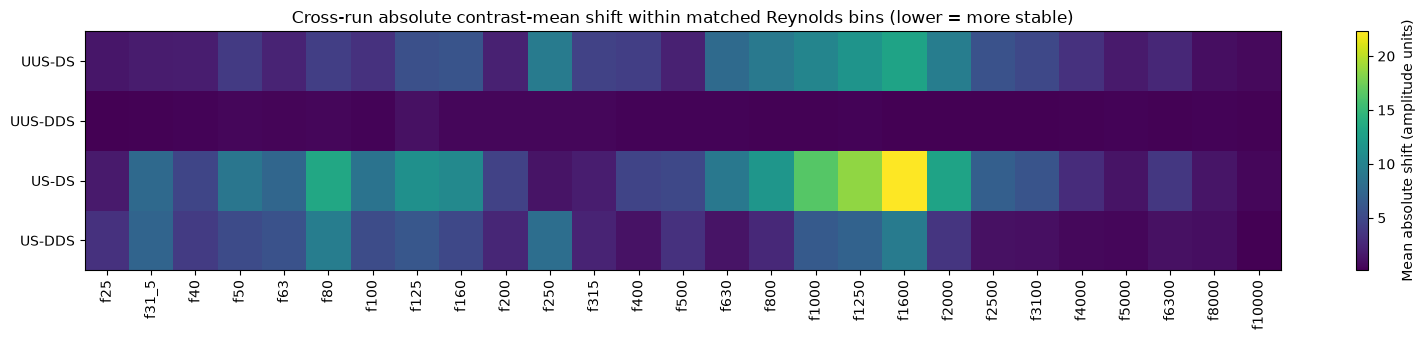

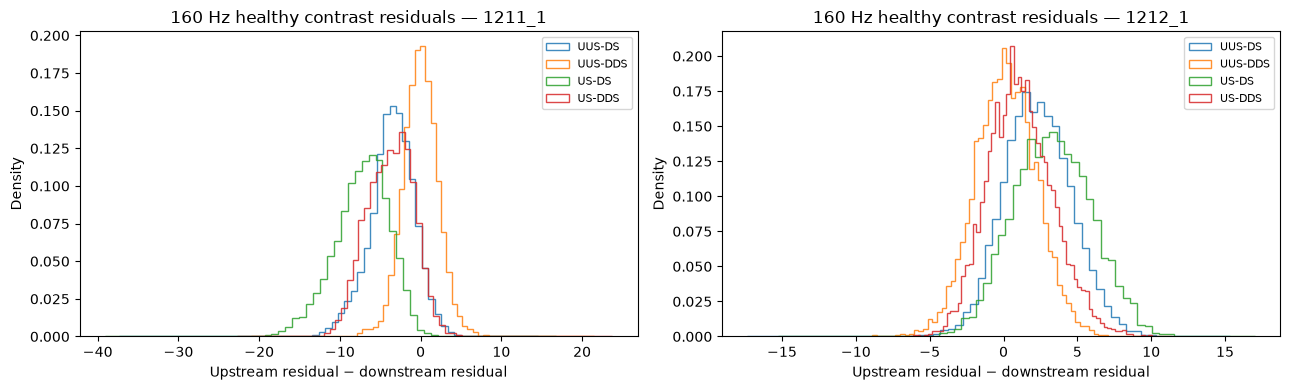

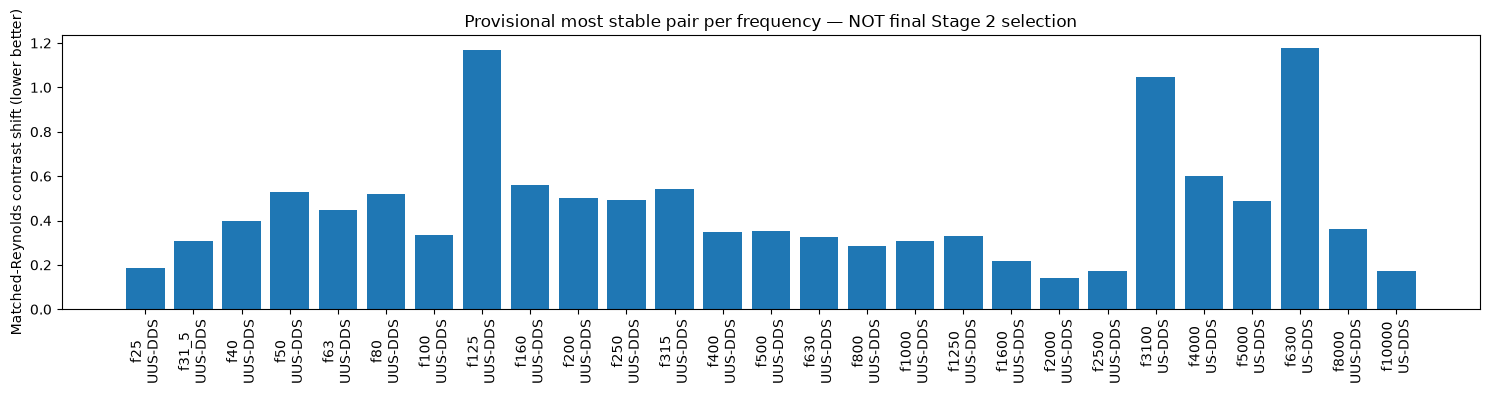

In [10]:
import matplotlib.pyplot as plt
order=sorted(FREQS,key=lambda s:float(s[1:].replace('_','.')))
mat=comparison.pivot(index='pair',columns='frequency',values='matched_abs_mean_shift').reindex(index=[f'{u}-{d}' for u,d in PAIRS],columns=order)
fig,ax=plt.subplots(figsize=(16,3.5))
im=ax.imshow(mat.to_numpy(),aspect='auto',cmap='viridis')
ax.set_yticks(range(len(mat.index)),mat.index)
ax.set_xticks(range(len(order)),order,rotation=90)
ax.set_title('Cross-run absolute contrast-mean shift within matched Reynolds bins (lower = more stable)')
fig.colorbar(im,ax=ax,label='Mean absolute shift (amplitude units)')
fig.tight_layout();fig.savefig(OUTPUT_DIR/'matched_reynolds_pair_stability_heatmap.png',dpi=160);plt.show()

fig,axs=plt.subplots(1,2,figsize=(13,4))
for ax,run in zip(axs,RUNS):
    d=runs[run];mask=d['label']=='healthy';j=FREQS.index('f160')
    for up,down in PAIRS:
        c=d['residual'][mask,PROBE_ORDER.index(up),j]-d['residual'][mask,PROBE_ORDER.index(down),j]
        ax.hist(c,bins=65,density=True,histtype='step',label=f'{up}-{down}',alpha=.85)
    ax.set_title(f'160 Hz healthy contrast residuals — {run}')
    ax.set_xlabel('Upstream residual − downstream residual');ax.set_ylabel('Density');ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(OUTPUT_DIR/'f160_pair_contrast_distributions.png',dpi=160);plt.show()

fig,ax=plt.subplots(figsize=(15,4))
short=shortlist.set_index('frequency').reindex(order)
ax.bar(range(len(short)),short.matched_abs_mean_shift)
ax.set_xticks(range(len(short)),[f'{f}\n{p}' for f,p in zip(short.index,short.pair)],rotation=90)
ax.set_ylabel('Matched-Reynolds contrast shift (lower better)')
ax.set_title('Provisional most stable pair per frequency — NOT final Stage 2 selection')
fig.tight_layout();fig.savefig(OUTPUT_DIR/'provisional_best_pairs.png',dpi=160);plt.show()


## 6. Interpretation and next decision

- **If UUS–DDS ranks best** at many frequencies, that supports the hypothesis of lower cross-run contrast drift, **not** proof of greater leak sensitivity.
- **If US–DS is unstable at 160 Hz**, the earlier Experiment A spatial contrast result is consistent with the pair-level analysis; note that this notebook additionally matches Reynolds ranges.
- **If there are no leak-labeled windows**, leak sensitivity remains **unknown**; no pair should be called leak-insensitive.
- **If there are few shared Reynolds bins**, cross-run comparisons are underidentified; mark as insufficient rather than choosing a winner.
- **No Stage 2 change is made.** Future work: select pairs on independent development runs and retrain/validate Stage 2 against the original four-probe baseline on held-out healthy and leak runs.

**Output CSVs and PNGs are in `results/experiment_C_probe_frequency_pairs/`.**